In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Question 1

In [14]:
fg = pd.read_csv('nndb_flat.csv')
fg.head()

,ID,FoodGroup,ShortDescrip,Descrip,CommonName,MfgName,ScientificName,Energy_kcal,Protein_g,Fat_g,...,Folate_USRDA,Niacin_USRDA,Riboflavin_USRDA,Thiamin_USRDA,Calcium_USRDA,Copper_USRDA,Magnesium_USRDA,Phosphorus_USRDA,Selenium_USRDA,Zinc_USRDA
0,1001,Dairy and Egg Products,"BUTTER,WITH SALT","Butter, salted",NaN,NaN,NaN,717.0,0.85,81.11,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000000,0.004762,0.034286,0.018182,0.008182
1,1002,Dairy and Egg Products,"BUTTER,WHIPPED,WITH SALT","Butter, whipped, with salt",NaN,NaN,NaN,717.0,0.85,81.11,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000018,0.004762,0.032857,0.018182,0.004545
2,1003,Dairy and Egg Products,"BUTTER OIL,ANHYDROUS","Butter oil, anhydrous",NaN,NaN,NaN,876.0,0.28,99.48,...,0.0000,0.000188,0.003846,0.000833,0.003333,0.000001,0.000000,0.004286,0.000000,0.000909
3,1004,Dairy and Egg Products,"CHEESE,BLUE","Cheese, blue",NaN,NaN,NaN,353.0,21.40,28.74,...,0.0900,0.063500,0.293846,0.024167,0.440000,0.000044,0.054762,0.552857,0.263636,0.241818
4,1005,Dairy and Egg Products,"CHEESE,BRICK","Cheese, brick",NaN,NaN,NaN,371.0,23.24,29.68,...,0.0500,0.007375,0.270000,0.011667,0.561667,0.000027,0.057143,0.644286,0.263636,0.236364


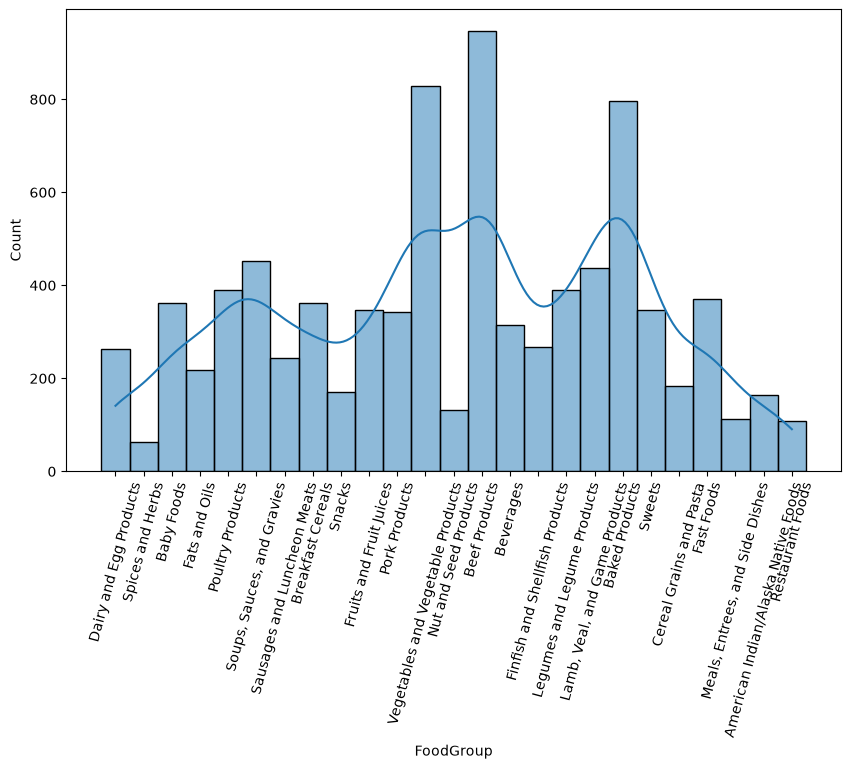

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(data=fg, x='FoodGroup', kde=True)
plt.xticks(rotation=75)
plt.show()

I would say that the histogram is overall well balanced with the exception of the categories: Beef Products, Vegetable and Vegetable Products, and Baked Products appearing the most frequently within the dataset by about 2-3 times more frequently than other categories.

In [16]:
fg["FoodGroup"].value_counts(ascending = False)

FoodGroup
Beef Products                          946
Vegetables and Vegetable Products      828
Baked Products                         797
Soups, Sauces, and Gravies             452
Lamb, Veal, and Game Products          438
Poultry Products                       390
Legumes and Legume Products            389
Fast Foods                             371
Breakfast Cereals                      363
Baby Foods                             362
Sweets                                 347
Fruits and Fruit Juices                346
Pork Products                          343
Beverages                              315
Finfish and Shellfish Products         267
Dairy and Egg Products                 264
Sausages and Luncheon Meats            244
Fats and Oils                          219
Cereal Grains and Pasta                183
Snacks                                 171
American Indian/Alaska Native Foods    165
Nut and Seed Products                  133
Meals, Entrees, and Side Dishes        113
R

In [17]:
fg.shape

(8618, 45)

In [18]:
fg_X_cols = fg.drop(columns = ["FoodGroup", "ID", "ShortDescrip", "Descrip", "CommonName", "MfgName", "ScientificName"])
plt.figure(figsize=(18, 15))
sns.pairplot(fg_X_cols)

<Figure size 1800x1500 with 0 Axes>

In [19]:
fg_wo_target.dtypes

ID                    int64
ShortDescrip            str
Descrip                 str
CommonName              str
MfgName                 str
ScientificName          str
Energy_kcal         float64
Protein_g           float64
Fat_g               float64
Carb_g              float64
Sugar_g             float64
Fiber_g             float64
VitA_mcg            float64
VitB6_mg            float64
VitB12_mcg          float64
VitC_mg             float64
VitE_mg             float64
Folate_mcg          float64
Niacin_mg           float64
Riboflavin_mg       float64
Thiamin_mg          float64
Calcium_mg          float64
Copper_mcg          float64
Iron_mg             float64
Magnesium_mg        float64
Manganese_mg        float64
Phosphorus_mg       float64
Selenium_mcg        float64
Zinc_mg             float64
VitA_USRDA          float64
VitB6_USRDA         float64
VitB12_USRDA        float64
VitC_USRDA          float64
VitE_USRDA          float64
Folate_USRDA        float64
Niacin_USRDA        

<Axes: >

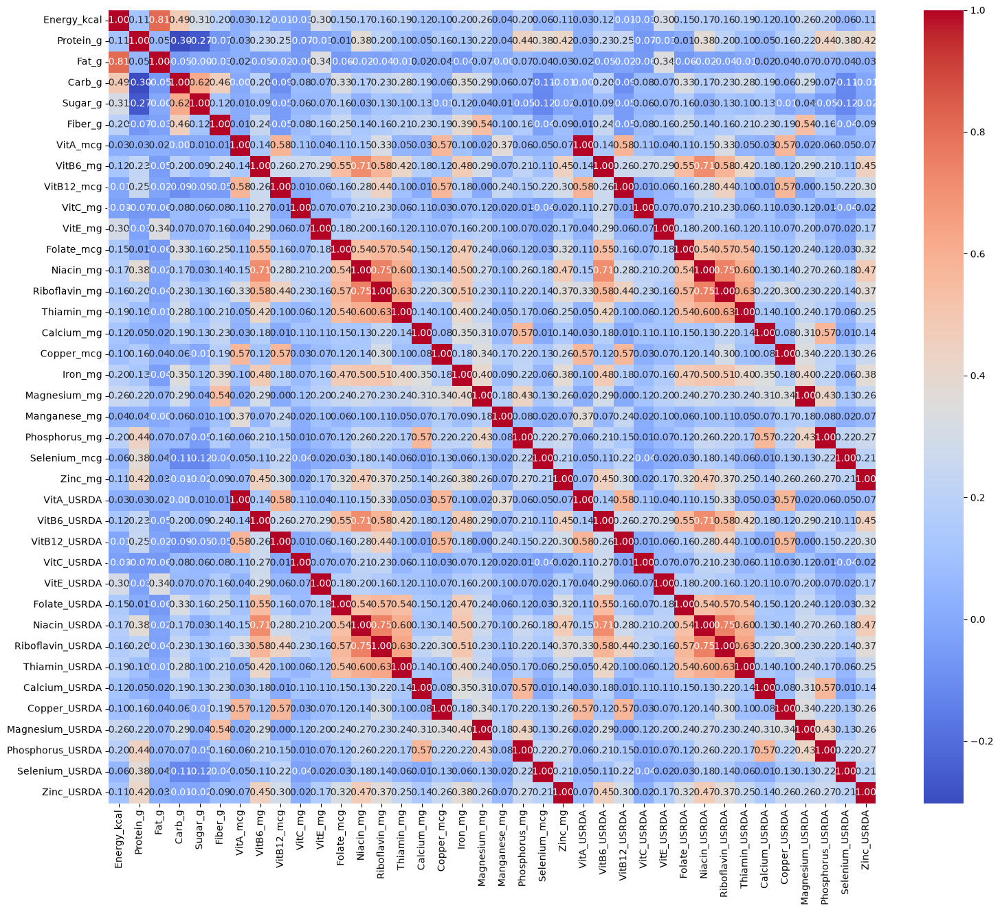

In [20]:
plt.figure(figsize=(18, 15))
sns.heatmap(fg_X_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")

    The heatmap works way better for this dataset than the pairplot since there are so many possible X values. The pairplot should really only be used with a small subset of columns since each possible variable pair needs its own scatterplot which sacrifices interpretability when the number of potenial feature values is high. With the heatmap, it is easy to observe a single correlation value for each pair compared to an entire scatterplot trend.

In [21]:
fg_X_cols.columns

Index(['Energy_kcal', 'Protein_g', 'Fat_g', 'Carb_g', 'Sugar_g', 'Fiber_g',
       'VitA_mcg', 'VitB6_mg', 'VitB12_mcg', 'VitC_mg', 'VitE_mg',
       'Folate_mcg', 'Niacin_mg', 'Riboflavin_mg', 'Thiamin_mg', 'Calcium_mg',
       'Copper_mcg', 'Iron_mg', 'Magnesium_mg', 'Manganese_mg',
       'Phosphorus_mg', 'Selenium_mcg', 'Zinc_mg', 'VitA_USRDA', 'VitB6_USRDA',
       'VitB12_USRDA', 'VitC_USRDA', 'VitE_USRDA', 'Folate_USRDA',
       'Niacin_USRDA', 'Riboflavin_USRDA', 'Thiamin_USRDA', 'Calcium_USRDA',
       'Copper_USRDA', 'Magnesium_USRDA', 'Phosphorus_USRDA', 'Selenium_USRDA',
       'Zinc_USRDA'],
      dtype='str')

       Based on the correlation heatmap, the USRDA percentage columns sahre a perfect linear combination with its absolute measurement counterparts (mg columns). Since including both sets for modeling would induce multicollineariyu, I will drop one set of those columns immediately: 
       'VitA_USRDA', 'VitB6_USRDA',
       'VitB12_USRDA', 'VitC_USRDA', 'VitE_USRDA', 'Folate_USRDA',
       'Niacin_USRDA', 'Riboflavin_USRDA', 'Thiamin_USRDA', 'Calcium_USRDA',
       'Copper_USRDA', 'Magnesium_USRDA', 'Phosphorus_USRDA', 'Selenium_USRDA',
       'Zinc_USRDA'   

In [22]:
fg_X_cols.drop(columns = ['VitA_USRDA', 'VitB6_USRDA',
       'VitB12_USRDA', 'VitC_USRDA', 'VitE_USRDA', 'Folate_USRDA',
       'Niacin_USRDA', 'Riboflavin_USRDA', 'Thiamin_USRDA', 'Calcium_USRDA',
       'Copper_USRDA', 'Magnesium_USRDA', 'Phosphorus_USRDA', 'Selenium_USRDA',
       'Zinc_USRDA'], inplace = True)

C:\Users\denni\AppData\Local\Temp\ipykernel_28424\1394264356.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  fg_X_cols.drop(columns = ['VitA_USRDA', 'VitB6_USRDA',


In [ ]:
# Looking for missingness
missingness_profile = pd.DataFrame({'Missing_Pct': fg_X_cols.isnull().mean() * 100,'Zero_Pct': (fg_X_cols == 0).mean() * 100})

print(missingness_profile.sort_values(by='Zero_Pct', ascending = False))

               Missing_Pct   Zero_Pct
VitC_mg                0.0  55.848225
Fiber_g                0.0  47.249942
VitB12_mcg             0.0  46.774194
Sugar_g                0.0  46.472499
VitA_mcg               0.0  46.240427
VitE_mg                0.0  39.754003
Folate_mcg             0.0  29.798097
Manganese_mg           0.0  26.583894
Carb_g                 0.0  24.622882
Selenium_mcg           0.0  24.147134
Copper_mcg             0.0  17.045718
VitB6_mg               0.0  14.841030
Thiamin_mg             0.0  11.638431
Niacin_mg              0.0  11.046647
Riboflavin_mg          0.0  11.000232
Magnesium_mg           0.0  10.431655
Zinc_mg                0.0  10.373637
Phosphorus_mg          0.0   9.166860
Calcium_mg             0.0   7.020190
Iron_mg                0.0   4.525412
Fat_g                  0.0   3.794384
Protein_g              0.0   3.747969
Energy_kcal            0.0   0.348109


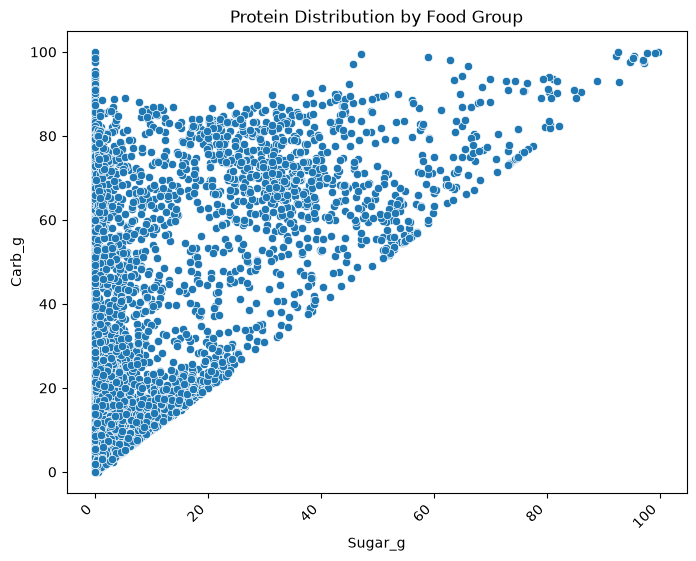

In [29]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=fg_X_cols, x='Sugar_g', y='Carb_g')
plt.xticks(rotation=45, ha='right')
plt.title("Protein Distribution by Food Group")
plt.show()

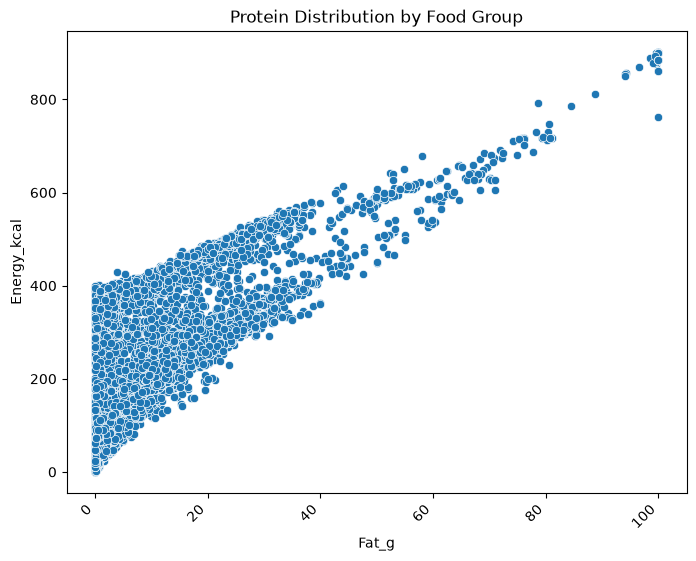

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=fg_X_cols, x='Fat_g', y='Energy_kcal')
plt.xticks(rotation=45, ha='right')
plt.title("Protein Distribution by Food Group")
plt.show()

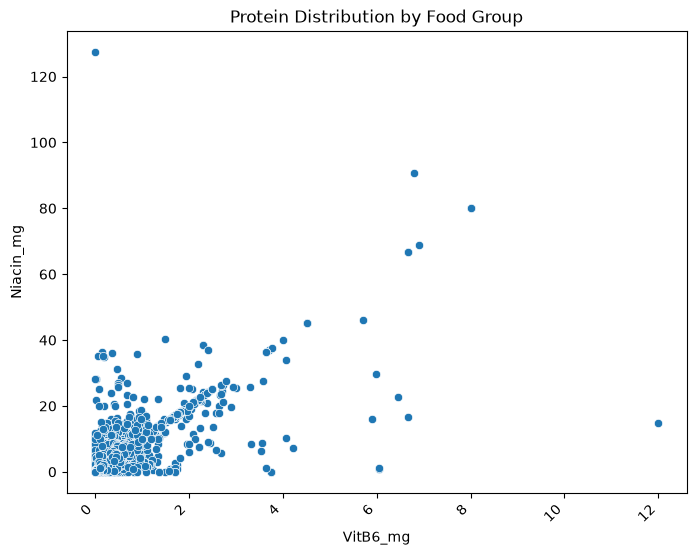

In [33]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=fg_X_cols, x='VitB6_mg', y='Niacin_mg')
plt.xticks(rotation=45, ha='right')
plt.title("Protein Distribution by Food Group")
plt.show()

       Candidate X set: 'Protein_g', 'Fat_g', 'Carb_g', 'Sugar_g', 'Fiber_g',
       'VitA_mcg', 'VitB12_mcg', 'Niacin_mg', 'VitE_mg',
       'Folate_mcg', , 'Thiamin_mg', 'Calcium_mg',
       'Copper_mcg', 'Iron_mg', 'Magnesium_mg', 'Manganese_mg',
       'Phosphorus_mg', 'Selenium_mcg', 'Zinc_mg'.

       I have removed Energy_kcal since it is strong correlated with Fat_g and we have the knowledge to create this feature using Fat_g, Carb_g and protein_g. I removed VitC_mg from the candiate set due to its high proportion of missing values. As for some of the vitamin relationship, I have remove vitamin groups from the candite feature set based on observed strong linear relationship between several pairs of vitamin groups. One example being removing VitB6_mg due to its strong linear relationship with Niacin_mg. Keeping Niacin_mg is beneficial since Riboflavin_mg has a strong linear correlation with Niacin_mg and a moderate to strong linear relationship with VitB6_mg.

       The candidate X set can be reduced further, but I believe this is one of the stronger ones you can make based on simple EDA plots I created.

In [ ]:
X_synthetic = pd.DataFrame()

X_synthetic['Sugar_to_Carb_Ratio'] = np.where(fg_X_cols['Carb_g'] > 0, fg_X_cols['Sugar_g'] / fg_X_cols['Carb_g'], 0)

X_synthetic['Total_Macros_g'] = fg_X_cols['Protein_g'] + fg_X_cols['Fat_g'] + fg_X_cols['Carb_g']

X_synthetic['Protein_to_Energy_Ratio'] = np.where(fg_X_cols['Energy_kcal'] > 0, (fg_X_cols['Protein_g'] * 4) / fg_X_cols['Energy_kcal'], 0)

X_synthetic['Net_Carbs_g'] = np.maximum(0, fg_X_cols['Carb_g'] - fg_X_cols['Fiber_g'])

In [38]:
X_synthetic.head(10)

,Sugar_to_Carb_Ratio,Total_Macros_g,Protein_to_Energy_Ratio,Net_Carbs_g
0,1.000000,82.02,0.004742,0.06
1,1.000000,82.02,0.004742,0.06
2,0.000000,99.76,0.001279,0.00
3,0.213675,52.48,0.242493,2.34
4,0.182796,55.71,0.250566,2.79
5,1.000000,48.88,0.248503,0.45
6,1.000000,44.52,0.264000,0.46
7,0.000000,57.44,0.267872,3.06
8,0.210526,59.19,0.236847,1.33
9,0.000000,58.75,0.241550,4.78


    Some of the syntethic Xs I created based on the feature engineering work includes a Net Carb feature which takes into account the Carbs plus fiber of an item all in one. I also created a total macronutrient variable as a food density proxy, protein to energy ratio to understand how lean and item might be, sugar to carb ratio to seperate foods such as cake and bread. Including some of these synthetic features can enable removing Xs used to engineer them, such as energy_kcal.

## Question 2

In [43]:
df = pd.read_csv("reg1.csv")
df.head()

,cust_sentiment,ads,satis,contact,econ1,econ2
0,44.657012,57.764230,10.716213,31.352358,8.825752,515.602000
1,86.588110,60.547010,9.592415,27.784756,8.638531,470.754586
2,72.956784,46.305818,11.400391,27.825407,8.041998,564.201090
3,127.721010,33.096335,9.710857,28.832871,12.678198,490.286382
4,72.738182,38.392287,7.370844,28.498596,12.097519,421.748301


In [52]:
def x_y_scatterplots(file_path: str, x_cols: list[str], y: str):

    data = pd.read_csv(file_path)

    for x in x_cols:
        plt.figure(figsize=(8, 6))
        plt.scatter(x = data[x], y = data[y], alpha = 0.8)
        plt.title(f"Relationship between {x} and {y}")
        plt.ylabel(f"target: {y}")
        plt.xlabel(f"feature: {x}")
        plt.show()



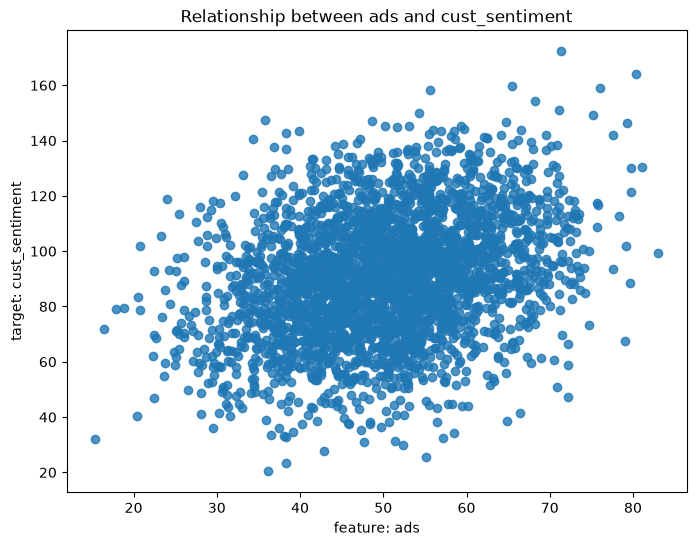

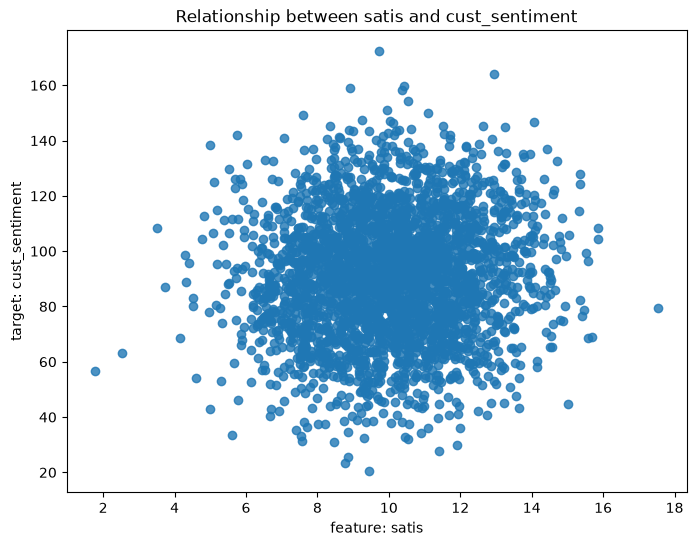

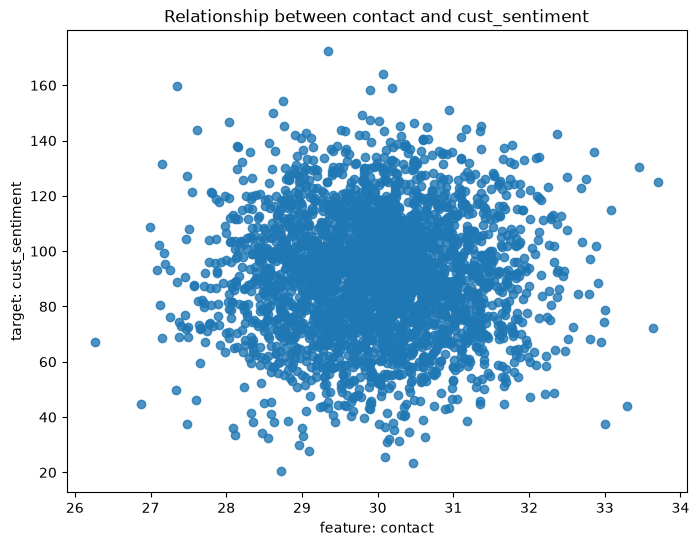

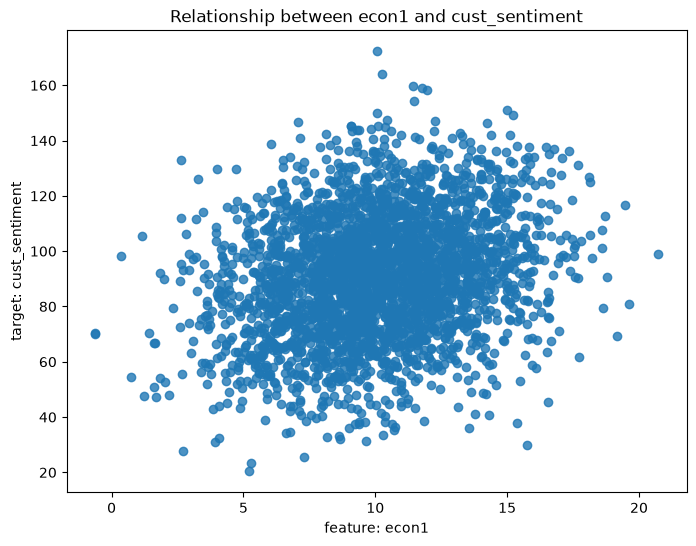

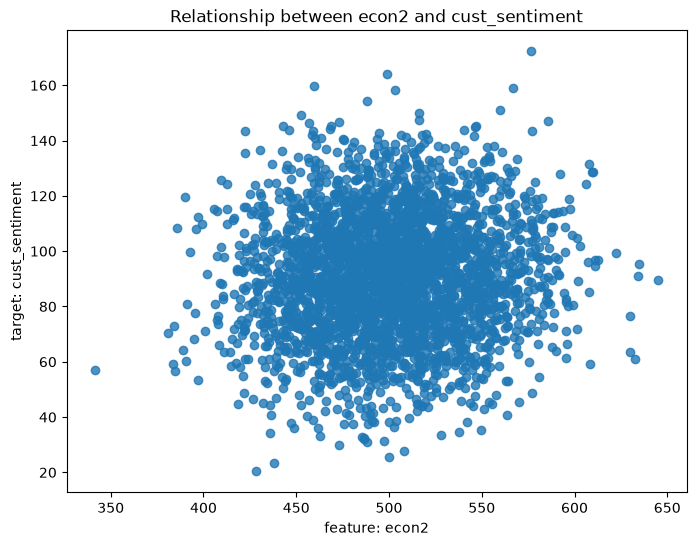

In [53]:
x_cols = ["ads", "satis", "contact", "econ1", "econ2"]
x_y_scatterplots(file_path = 'reg1.csv', x_cols = x_cols, y = "cust_sentiment")

## Question 5

Making the mistake of predicting no heart attack when there in fact is one (False Negative) is much worse than the other way arround. The cost with this error is much higher than the oppostite, predicting heart attack when there isnt one (False Positive). For a FP we can assign treatment to the patient, monitor them and provide overall medical assisatnce, however a FN can result in death or more expensive procedures such as intensive surgeries, ect. 

A false negative in classification terms it means we predict the negative class when in fact the true label is positive. For this problem within the classification task, our goal is to then minimize false negatives, which can be done by assessing the Recall metric (TP / TP + FP). Ideally we want this to be as close as possible to 1, which means that the FP count is 0. The way I will implement this within the model is by penalizing mistakes for the positive class more than classification mistakes for the negative class.

In [157]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, precision_score, f1_score, precision_recall_curve, roc_curve, roc_auc_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [158]:
heart = pd.read_csv("Heart.csv")
heart = heart.drop(columns = ['Unnamed: 0'])
heart.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [159]:
heart["target"] = np.where(heart["AHD"] == 'Yes', 1, 0)

heart = heart.drop(columns = ['AHD'])

In [160]:
heart.columns

Index(['Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR',
       'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'target'],
      dtype='str')

In [161]:
# Training a LR classifier with default parameters and no penalization on getting positive class predictions incorrect

lr = LogisticRegression(random_state=51, max_iter=1000)
preprocessor = ColumnTransformer(
    transformers = [
        ('categorical', OneHotEncoder(sparse_output= False, handle_unknown= "ignore"), ['Thal', 'ChestPain']),
        ('num', StandardScaler(), ['Age', 'RestBP', 'Chol', 'MaxHR', 'Oldpeak'])
        ],
    remainder = 'passthrough'
)

X_train, X_test, y_train, y_test = train_test_split(heart.drop(columns = 'target'), heart["target"], test_size= 0.2, random_state= 51)

preprocessor.set_output(transform= "pandas")

X_train_ohe = preprocessor.fit_transform(X_train)

X_test_ohe = preprocessor.transform(X_test)

In [162]:
print((X_train_ohe['categorical__Thal_nan'] == 1).mean())
print((X_train_ohe['categorical__Thal_nan'] == 1).sum())
print(X_train_ohe.isna().any(axis=1).sum())

print((X_test_ohe['categorical__Thal_nan'] == 1).mean())
print(X_test_ohe.isna().any(axis=1).sum())

0.008264462809917356
2
4
0.0
0


Since there are only 6 rows within the training set with missing values, I will drop those rows before fitting the LR classifier since they are not allowed.

In [163]:
valid_rows = (X_train_ohe['categorical__Thal_nan'] != 1) & (~X_train_ohe.isna().any(axis=1))
X_train_ohe = X_train_ohe[valid_rows]
y_train = y_train[valid_rows]

In [168]:
lr.fit(X_train_ohe, y_train)

y_hat = lr.predict(X_test_ohe)

accuracy = accuracy_score(y_test, y_hat)
recall = recall_score(y_test, y_hat)
precision = precision_score(y_test, y_hat)
au_roc = roc_auc_score(y_test, y_hat)
auc_pr, auc_r, _ = precision_recall_curve(y_test, y_hat)
print(f"Accuracy: {accuracy:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Precision: {precision:.4f}")
print(f"AU-ROC: {au_roc:.4f}")

Accuracy: 0.8525
Recall: 0.9200
Precision: 0.7667
AU-ROC: 0.8628


In [170]:
confusion_matrix(y_test, y_hat)

array([[29,  7],
       [ 2, 23]])

From the confusion matrix we have 2 false negatives. In the context of the heart problem that means we predict for 2 patients that they will not have a heart attack when they in fact do. Ideally wed like to get that to 0 which would maximize recall. Here I will to assign a larger penalty to errors for the positive class within the loss function to see if the number of FNs drop from 2 and are able to minimize the more costly mistake.

In [177]:
lr2 = LogisticRegression(random_state=51, max_iter=1000, class_weight={0: 1, 1: 5})

lr2.fit(X_train_ohe, y_train)

y_hat = lr2.predict(X_test_ohe)

accuracy = accuracy_score(y_test, y_hat)
recall = recall_score(y_test, y_hat)
precision = precision_score(y_test, y_hat)
au_roc = roc_auc_score(y_test, y_hat)
auc_pr, auc_r, _ = precision_recall_curve(y_test, y_hat)
print(f"Accuracy: {accuracy:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Precision: {precision:.4f}")
print(f"AU-ROC: {au_roc:.4f}")

Accuracy: 0.8033
Recall: 1.0000
Precision: 0.6757
AU-ROC: 0.8333


In [178]:
confusion_matrix(y_test, y_hat)

array([[24, 12],
       [ 0, 25]])

From the output of the classification matrix, we can see that we have no incorrect predictions for the positive class, ie we have minimized the most costly mistakes. Ideally we want to reduce the number of false postives as well since the since there are quite a several incorrect classification predictions for the true negative class labels. Obviously my model is not at a final production level, but enough to illustrate minimizing the most costly error based on the domain.